# Analyse transversale des résultats de l'expérience 5 (perturbation de niveau multiples)

Les résultats de l'activation patching sont sous l'_ancienne représentation_.

In [2]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Chargement des résultats de l'expé

In [3]:
filepath = "res/mE5-MainV2/exp5/synonymes/perts_values.json"
with open(filepath, 'r', encoding="utf-8") as load_file:
        syn_values =  json.load(load_file)

In [4]:
filepath = "res/mE5-MainV2/exp5/polysemie/perts_values.json"
with open(filepath, 'r', encoding="utf-8") as load_file:
        ps_values =  json.load(load_file)

In [5]:
filepath = "res/mE5-MainV2/exp5/elephants/perts_values.json"
with open(filepath, 'r', encoding="utf-8") as load_file:
        el_values =  json.load(load_file)

In [6]:
filepath = "res/mE5-MainV2/exp5/elephants-roses/perts_values.json"
with open(filepath, 'r', encoding="utf-8") as load_file:
        er_values =  json.load(load_file)

In [7]:
perts = list(syn_values.keys())

Fontions utiles

In [8]:
def get_friend(pert_name, x_values):
    pert_name_compo = pert_name.split("->")
    for p_name, p_vals in x_values.items():
        if pert_name_compo[0].strip() in p_name:
            return p_vals
    

## Perturbation de l'espace pour un même mot de départ

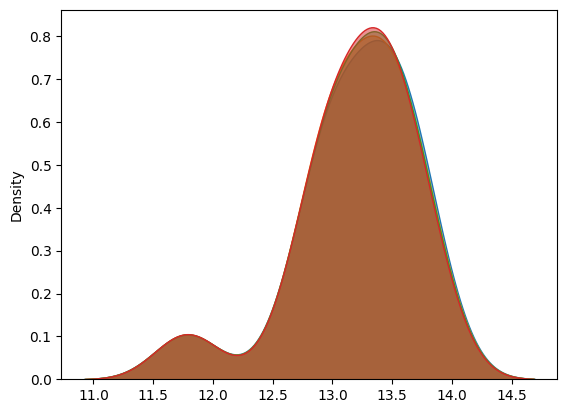

In [9]:
n_row, n_col = 2,4
fig, ax = plt.subplots()#n_row,n_col

i=0
for pert_A in syn_values:
    for values in [syn_values, ps_values, el_values, er_values]:
        #ax[i//3][i%3].plot(get_friend(pert_A, values)["perturbed_perf"])
        sns.kdeplot(get_friend(pert_A, values)["perturbed_perf"], fill=True, ax=ax, alpha=0.5)# [i//n_col][i%n_row]
    plt.show()
    i +=1


In [10]:

for pert_A in syn_values:
    print(pert_A, "& friends", 10*"=")
    for values in [syn_values, ps_values, el_values, er_values]:
        print(get_friend(pert_A, values)["perturbed_perf"])
    

aérien -> de vol & friends ==========
[11.715386390686035, 13.343062400817871, 13.4991455078125, 13.651016235351562, 13.379152297973633, 13.030975341796875, 13.51997184753418, 13.377400398254395, 13.713604927062988, 13.185818672180176, 12.97866153717041, 13.659361839294434, 13.59189510345459, 11.856109619140625, 13.817214965820312, 13.898619651794434, 13.666997909545898, 12.882928848266602, 12.96495246887207, 13.300960540771484, 12.839133262634277, 12.625608444213867, 12.9100341796875, 13.363997459411621, 12.990272521972656, 12.951096534729004, 13.223237991333008, 13.483081817626953]
[11.715386390686035, 13.26286792755127, 13.518891334533691, 13.651450157165527, 13.379152297973633, 13.030975341796875, 13.449058532714844, 13.377400398254395, 13.713604927062988, 13.185818672180176, 12.97866153717041, 13.659361839294434, 13.521175384521484, 11.856109619140625, 13.817214965820312, 13.898619651794434, 13.666997909545898, 12.882928848266602, 12.96495246887207, 13.300960540771484, 12.83913326

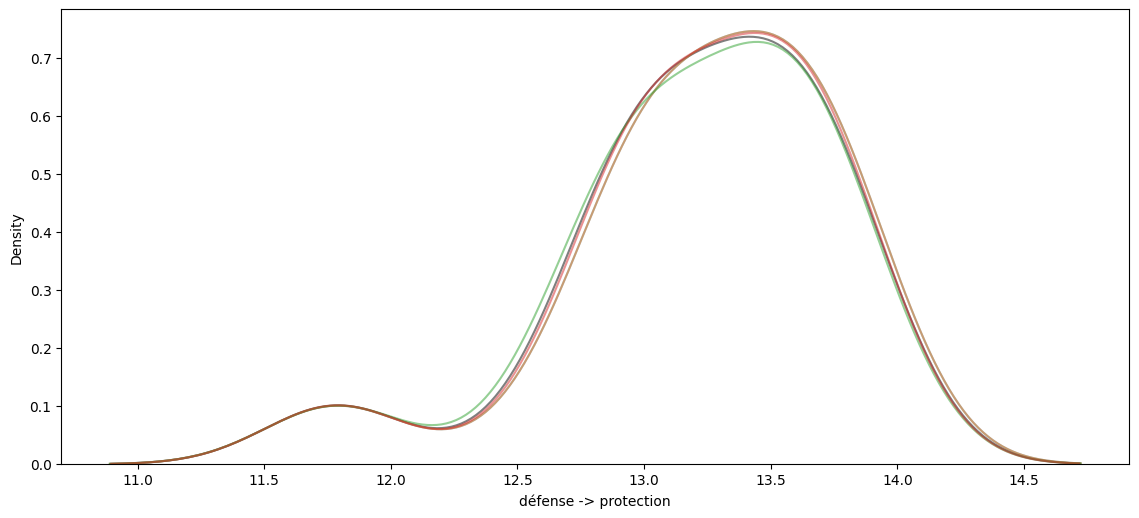

In [11]:
choix=2
cm = 1/2.54
fig, ax = plt.subplots(figsize=(35*cm, 15*cm))
sns.kdeplot(get_friend(perts[0], values)["baseline_perf"], fill=False, ax=ax, alpha=0.5, label="BL", color="k")# [i//n_col][i%n_row]
for values in [ps_values, ps_values, el_values, er_values]:
    #ax[i//3][i%3].plot(get_friend(pert_A, values)["perturbed_perf"])
    sns.kdeplot(get_friend(perts[choix], values)["perturbed_perf"], fill=False, ax=ax, alpha=0.5)# [i//n_col][i%n_row]
    ax.set_xlabel(perts[choix])
plt.show()

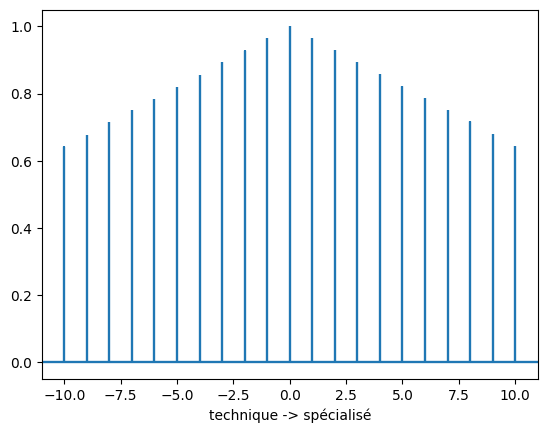

In [12]:
choix=7
fig, ax = plt.subplots()
for values in [syn_values, ps_values, el_values, er_values]:
    #ax[i//3][i%3].plot(get_friend(pert_A, values)["perturbed_perf"])
    #sns.kdeplot(get_friend(perts[choix], values)["perturbed_perf"], fill=False, ax=ax, alpha=0.5)# [i//n_col][i%n_row]
    ax.xcorr(get_friend(perts[0], values)["perturbed_perf"], get_friend(perts[choix], values)["perturbed_perf"])
    ax.set_xlabel(perts[choix])
plt.show()

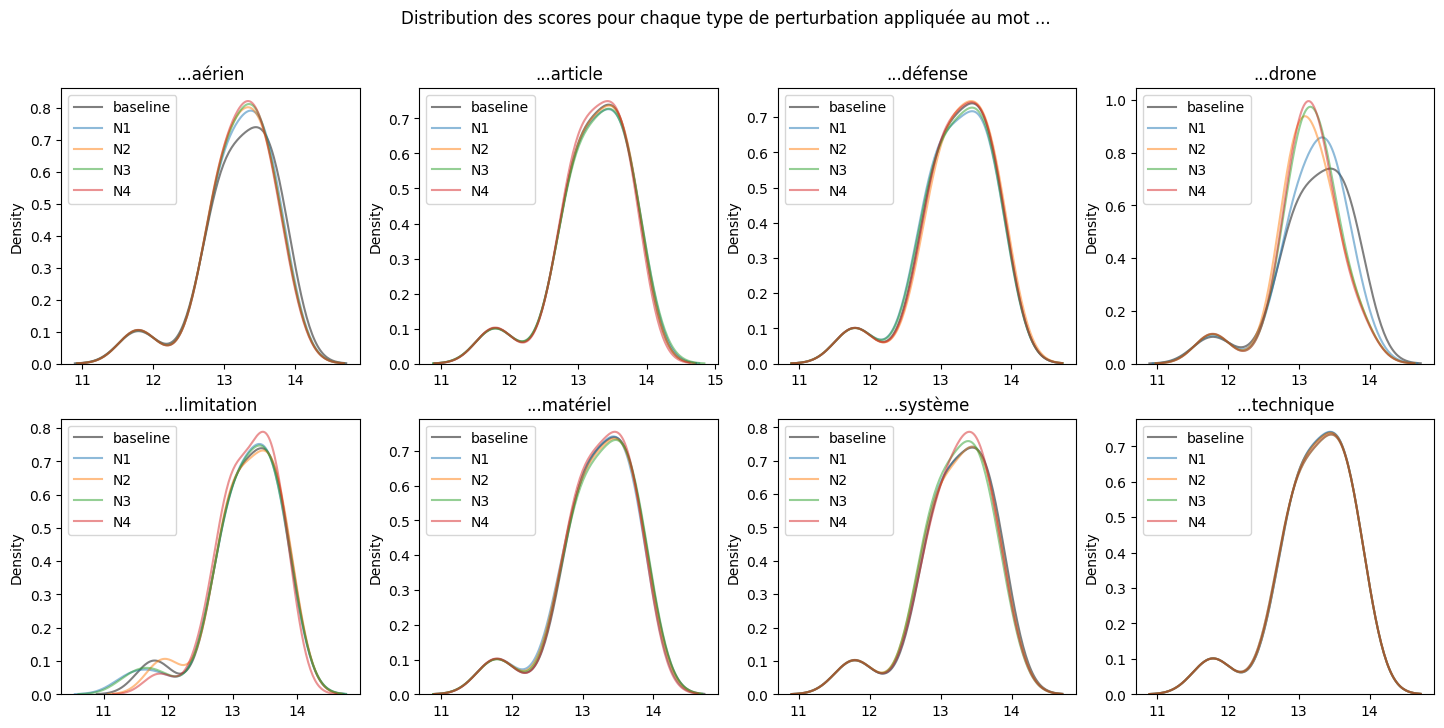

In [18]:
choix=5
cm = 1/2.54  # centimeters in inches
fig, ax = plt.subplots(2,4, figsize=(45*cm, 20*cm))

niv_label = ["N1", "N2", "N3", "N4"]

for i in range(len(perts)):
    j=0
    sns.kdeplot(get_friend(perts[0], syn_values)["baseline_perf"], fill=False, ax=ax[i//4][i%4], alpha=0.5, label="baseline", color="k")# [i//n_col][i%n_row]
    for values in [syn_values, ps_values, el_values, er_values]:
        #ax[i//3][i%3].plot(get_friend(pert_A, values)["perturbed_perf"])
        sns.kdeplot(get_friend(perts[i], values)["perturbed_perf"], fill=False, ax=ax[i//4][i%4], alpha=0.5, label=niv_label[j])# [i//n_col][i%n_row]
        ax[i//4][i%4].set_title("..."+perts[i].split("->")[0].strip())
        ax[i//4][i%4].legend()
        j+=1
fig.suptitle("Distribution des scores pour chaque type de perturbation appliquée au mot ...")
plt.show()

## Noeuds sensibles pour un même mot de départ

In [13]:
def get_noeuds_sensibles(pert_values):
    """
    Compte le nombre de perturbations pour lesquelles chaque noeud
    est considéré comme sensible.

    Parameters
    ----------
    pert_values : str
        Dictionnaire contennat les matrices de moyennes de sensibilité (`patching_mean`) et d'écarts-types de sensibilité (`patching_std`) 

    est_sensible : callable
        Fonction prenant (mean, std) et renvoyant True ou False.

    Returns
    -------
    dict 
        Noeuds sensibles selon `est_sensible` et leurs valeurs
    int
        Nobre total de noeuds identifiés
    List(List(bool))
        Indicatrice des noeuds sensibles
    """

    shape = np.array(pert_values).shape

    noeuds_sensibles =  {}

    mean = np.array(pert_values["patching_mean"])
    std = np.array(pert_values["patching_std"])
    resc_mean = (np.sign(mean) / np.absolute(mean).max()) * np.absolute(mean)
    resc_std = (np.sign(std) / np.absolute(std).max()) * np.absolute(std)

    carte = ((np.abs(mean) > 0.1) & (np.abs(resc_mean) > 0.5)) | (resc_std > 0.5)

    
    for i in range(mean.shape[0]):
        for j in range(mean.shape[1]):
            if carte[i,j]:
                noeuds_sensibles[(i,j)] = (mean[i,j], std[i,j], resc_mean[i,j], resc_std[i,j])

    total = np.sum(carte)

    return noeuds_sensibles, total, carte

In [14]:


def plot_component_mix(
    matrices,
    component_colors,
    normalize="global",
    title="Component mixture"
):
    """
    Affiche une matrice colorée obtenue par combinaison linéaire
    de plusieurs matrices de composantes.

    Parameters
    ----------
    matrices : list[np.ndarray]
        Liste de k matrices de même taille.

    component_colors : list[tuple]
        Liste de k couleurs RGB.
        Exemple :
        [
            (1,0,0),   # rouge
            (0,1,0),   # vert
            (0,0,1),   # bleu
            (1,1,0)    # jaune
        ]

    normalize : str
        "global" : normalisation sur l'ensemble des matrices.
        "local"  : normalisation cellule par cellule.
        None     : pas de normalisation.

    title : str
        Titre du graphique.
    """

    k = len(matrices)

    if k != len(component_colors):
        raise ValueError(
            "Nombre de matrices et nombre de couleurs différents"
        )

    shape = matrices[0].shape

    for m in matrices:
        if m.shape != shape:
            raise ValueError("Toutes les matrices doivent avoir la même taille")

    data = np.stack(matrices, axis=-1)

    # ------------------------
    # Normalisation
    # ------------------------

    if normalize == "global":

        max_val = data.max()

        if max_val > 0:
            data = data / max_val

    elif normalize == "local":

        sums = data.sum(axis=-1, keepdims=True)

        sums[sums == 0] = 1

        data = data / sums

    # ------------------------
    # Mélange des couleurs
    # ------------------------

    colors = np.asarray(component_colors)

    rgb = np.tensordot(data, colors, axes=([2], [0]))

    print(rgb)

    #rgb = np.clip(rgb, 0, 1) * 255
    #rgb = (rgb / np.max(np.abs(rgb))) * 255


    # ------------------------
    # Affichage
    # ------------------------

    plt.figure(figsize=(10, 8))

    plt.imshow(rgb, origin="upper")

    totals = np.sum(np.stack(matrices, axis=-1), axis=-1)

    for i in range(totals.shape[0]):
        for j in range(totals.shape[1]):
            brightness = np.mean(rgb[i, j])
            text_color = "white" if brightness < 0.5 else "black"
            plt.text(
                j,
                i,
                f"{totals[i,j]:.0f}",
                ha="center",
                va="center",
                color=text_color
            )

    plt.xlabel("Attention head")
    plt.ylabel("Layer")

    plt.title(title)

    plt.tight_layout()
    plt.show()

[[[0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.5 0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]]

 [[0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]]

 [[0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]]

 [[0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]]

 [[0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]
  [0.  0.  0. ]]

 [[0.  0.  0. ]
  [0.  0.  0. 

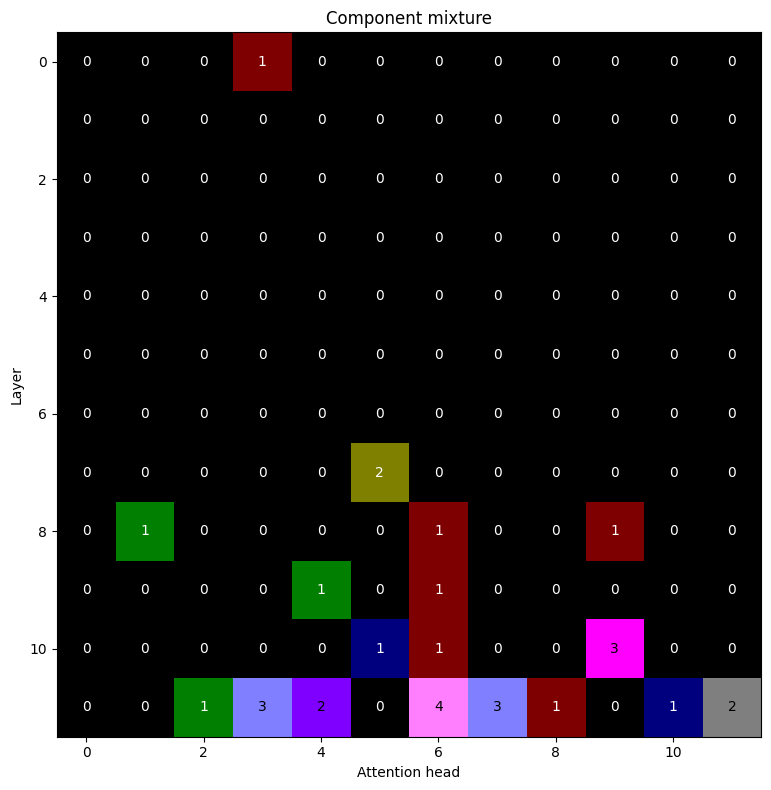

In [15]:
ns_syn, total_syn, carte_syn = get_noeuds_sensibles(syn_values[perts[0]])
ns_ps, total_ps, carte_ps = get_noeuds_sensibles(get_friend(perts[0], ps_values))
ns_el, total_el, carte_el = get_noeuds_sensibles(get_friend(perts[0], el_values))
ns_er, total_er, carte_er = get_noeuds_sensibles(get_friend(perts[0], er_values))

#carte_syn, carte_ps, carte_el, carte_er = np.asarray(carte_syn), np.asarray(carte_ps), np.asarray(carte_el), np.asarray(carte_er)
cartes_np = [np.asarray(carte_syn).astype(int), np.asarray(carte_ps).astype(int), np.asarray(carte_el).astype(int), np.asarray(carte_er).astype(int)]

plot_component_mix(
    cartes_np,
    [
            (0.5,0,0),   # rouge
            (0,0.5,0),   # vert
            (0,0,0.5),   # bleu
            (0.5,0,0.5)    # violet
        ],
    normalize=None,
    title="Component mixture"
)

[[[1 1 0]
  [0 0 0]]

 [[1 0 0]
  [0 1 0]]]


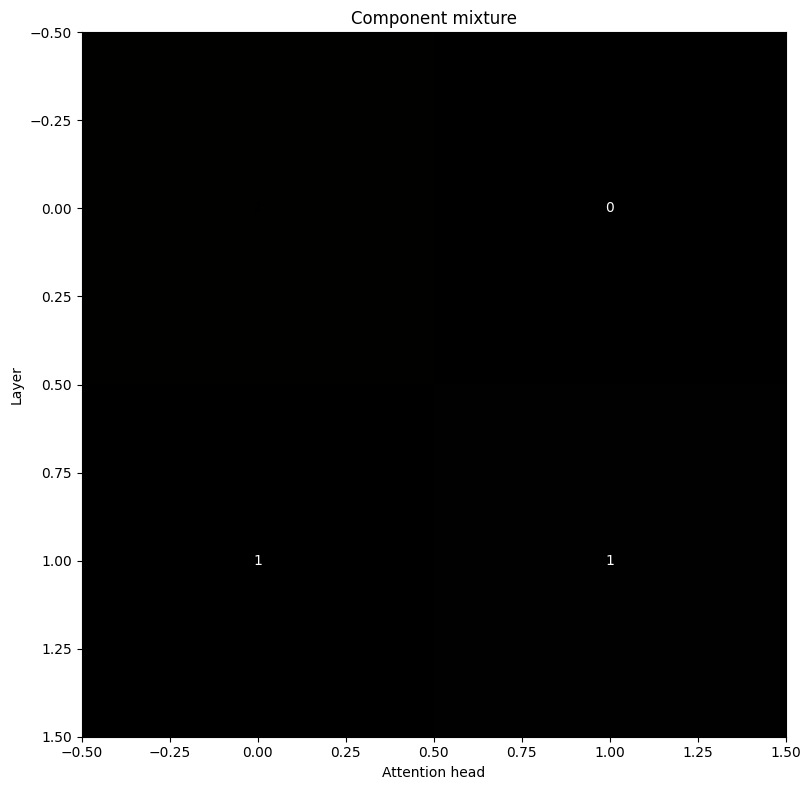

In [16]:
mat1 = [[1,0],[1,0]]
mat2 = [[1,0],[0,1]]

mats = [np.asarray(mat1), np.asarray(mat2)]
cols = [(1,0,0), (0,1,0)]

plot_component_mix(
    mats,
    cols,
    normalize=None,
    title="Component mixture"
)

[[0 0 0 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 2 0 0 0 0 0 0]
 [0 1 0 0 0 0 1 0 0 1 0 0]
 [0 0 0 0 1 0 1 0 0 0 0 0]
 [0 0 0 0 0 1 1 0 0 3 0 0]
 [0 0 1 3 2 0 4 3 1 0 1 2]]


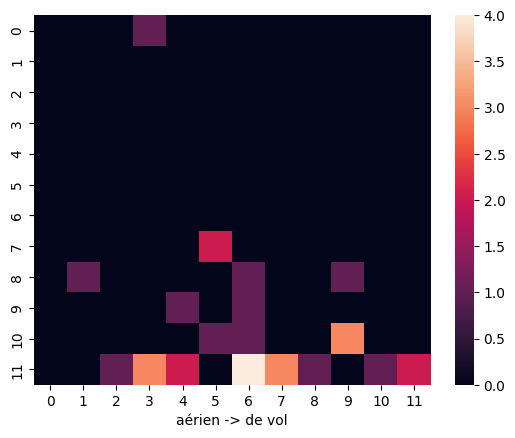

In [17]:
i=0

fig, ax = plt.subplots()

ns_syn, total_syn, carte_syn = get_noeuds_sensibles(syn_values[perts[i]])
ns_ps, total_ps, carte_ps = get_noeuds_sensibles(get_friend(perts[i], ps_values))
ns_el, total_el, carte_el = get_noeuds_sensibles(get_friend(perts[i], el_values))
ns_er, total_er, carte_er = get_noeuds_sensibles(get_friend(perts[i], er_values))

carte = np.sum(np.asarray([carte_syn, carte_ps, carte_el, carte_er]), axis=0)
print(carte)
ax = sns.heatmap(
    carte,
    # cmap=view_params["cmap"], 
    # vmin=view_params["vmin"],
    # vmax=view_params["vmax"],
    # xticklabels=True,
    # yticklabels=True,
    # fmt=".2f",
    # annot=True,
    # annot_kws={"size": 8},
)

ax.set_xlabel(perts[i])

plt.show()

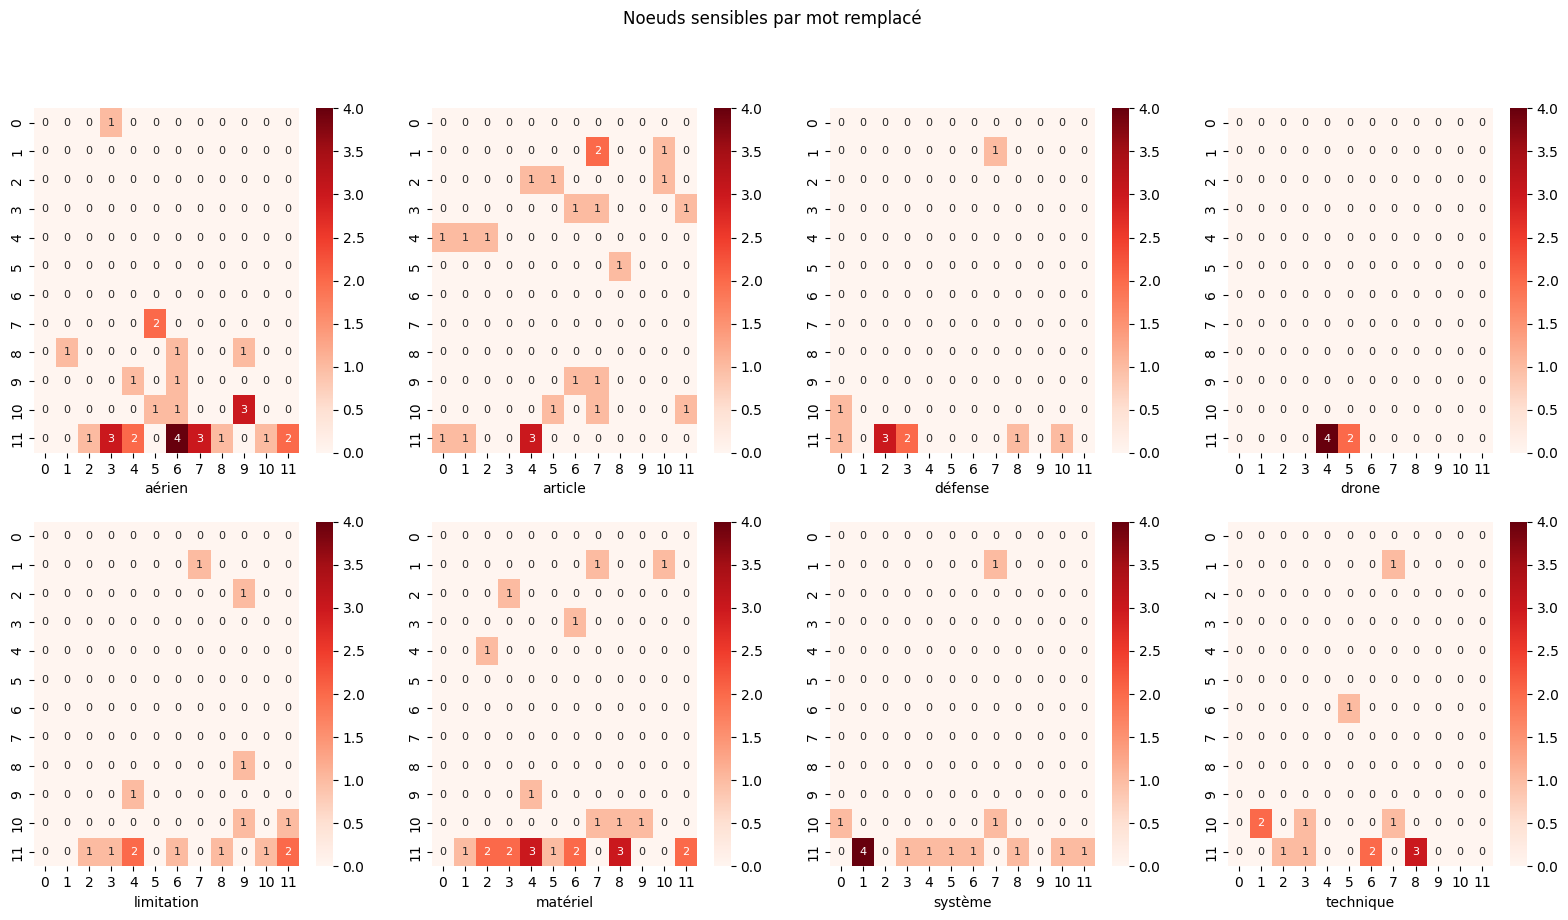

In [18]:
cm = 1/2.54  # centimeters in inches
fig, ax = plt.subplots(2,4, figsize=(50*cm, 25*cm))

for i in range(len(perts)):
    ns_syn, total_syn, carte_syn = get_noeuds_sensibles(syn_values[perts[i]])
    ns_ps, total_ps, carte_ps = get_noeuds_sensibles(get_friend(perts[i], ps_values))
    ns_el, total_el, carte_el = get_noeuds_sensibles(get_friend(perts[i], el_values))
    ns_er, total_er, carte_er = get_noeuds_sensibles(get_friend(perts[i], er_values))

    carte = np.sum(np.asarray([carte_syn, carte_ps, carte_el, carte_er]), axis=0)
    #print(carte)
    sns.heatmap(
        carte,
        ax=ax[i//4][i%4],
        cmap="Reds", 
        vmin=0,
        vmax=4,
        xticklabels=True,
        yticklabels=True,
        annot=True,
        annot_kws={"size": 8},
    )

    ax[i//4][i%4].set_xlabel(perts[i].split("->")[0].strip())
fig.suptitle("Noeuds sensibles par mot remplacé")

plt.show()



In [34]:

from matplotlib.ticker import MaxNLocator

def plot_score_dists_mult(all_baseline_scores, all_perturbed_scores, plot_type="hist", save_path = None):
    # Number of subplots (one per perturbation type)
    num_plots = len(all_baseline_scores)

    # Set up the figure to hold multiple subplots in a single row
    fig, axs = plt.subplots(1, num_plots, figsize=(15, 4), sharey=True)
    fig.suptitle('Distribution of Baseline vs Perturbed Scores', fontsize=16)

    for idx, (perturb_type, ax) in enumerate(zip(all_baseline_scores.keys(), axs)):
        baseline_scores = all_baseline_scores[perturb_type]
        perturbed_scores = all_perturbed_scores[perturb_type]

        if plot_type == "hist":
            ax.hist(baseline_scores, label='Baseline', color='blue', alpha=0.5, bins=15)
            ax.hist(perturbed_scores, label='Perturbed', color='orange', alpha=0.5, bins=15)
            ax.yaxis.set_major_locator(MaxNLocator(integer=True))
            ax.set_ylabel('Frequency')
            ax.legend()
        elif plot_type == "kde":
            # Use seaborn for KDE plot, smoother distribution representation
            sns.kdeplot(baseline_scores, label='Baseline', color='#D55E00', fill=True, ax=ax, alpha=0.5)
            sns.kdeplot(perturbed_scores, label='Perturbed', color='#009E73', fill=True, ax=ax, alpha=0.5)
            ax.set_ylabel('Density')
            ax.legend()
        elif plot_type == "box":
            ax.boxplot([baseline_scores, perturbed_scores], tick_labels=['Baseline', 'Perturbed'])
            ax.set_ylabel('Scores')

        ax.set_xlabel('Distances between R(q) and R(d)')
        ax.set_title(f'{perturb_type.capitalize()}')

     #plt.tight_layout(rect=[0, 0, 1, 0.95])  # Adjust layout to make space for the title
    if save_path is not None:
        plt.savefig(save_path)
        plt.close()
    else:
        plt.show()

    return


all_baseline_scores = []
all_perturbed_scores = []
for i in range(len(perts)):
    all_baseline_scores[perts[i].split("->")[0].strip()] = get_friend(perts[i], syn_values)["baseline_perf"]
    all_perturbed_scores[perts[i].split("->")[0].strip()] = get_friend(perts[i], syn_values)["perturbed_perf"]

plot_score_dists_mult(all_baseline_scores, all_perturbed_scores, plot_type="box")

TypeError: list indices must be integers or slices, not str